# TMDB Movie Data Analysis with Spark and PySpark
End-to-end pipeline: **fetch** movie data from the TMDB API → **clean & transform** it with PySpark → compute **KPIs** → **visualize** the results → generate a **final report**.

## Setup
Imports, project paths, API settings and the movie IDs to analyse. The TMDB key is read from a `.env` file (`TMDB_API_KEY=...`) so it never ends up in Git.

In [1]:
!pip install -r requirements.txt


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import json
import logging
import os
from functools import reduce
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests
from dotenv import load_dotenv
from pyspark.sql import DataFrame, SparkSession, Window
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType, IntegerType
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

load_dotenv()
logging.basicConfig(level=logging.INFO, format="%(levelname)s | %(message)s")
logger = logging.getLogger("tmdb")

# Paths (works whether the notebook sits in the project root or in /notebooks)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR, PROCESSED_DIR = ROOT / "data" / "raw", ROOT / "data" / "processed"
REPORTS_DIR, FIGURES_DIR = ROOT / "reports", ROOT / "reports" / "figures"
for d in (RAW_DIR, PROCESSED_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)

# TMDB API
TMDB_BASE_URL = "https://api.themoviedb.org/3"
TMDB_API_KEY = os.getenv("TMDB_API_KEY")

MOVIE_IDS = [0, 299534, 19995, 140607, 299536, 597, 135397,
             420818, 24428, 168259, 99861, 284054, 12445,
             181808, 330457, 351286, 109445, 321612, 260513]

# Extra movies used ONLY to prove the search queries work (never mixed into the KPIs)
SEARCH_VALIDATION_IDS = [18, 95, 59967, 562, 680, 24, 393]

DROP_COLUMNS = ["adult", "imdb_id", "original_title", "video", "homepage"]
FINAL_COLUMNS = ["id", "title", "tagline", "release_date", "genres", "belongs_to_collection",
                 "original_language", "budget_musd", "revenue_musd", "production_companies",
                 "production_countries", "vote_count", "vote_average", "popularity", "runtime",
                 "overview", "spoken_languages", "poster_path", "cast", "cast_size", "director",
                 "crew_size"]
TEXT_PLACEHOLDERS = ["", "no data", "n/a", "na", "none", "null", "no overview found.",
                     "no overview found", "no overview", "-", "tbd"]

## Spark Session
A local Spark session. Shuffle partitions are reduced from 200 to 8 because the dataset is tiny: 200 partitions would only add overhead.

In [3]:
!java -version

openjdk version "17.0.21" 2026-10-20
OpenJDK Runtime Environment Temurin-17.0.21+9 (build 17.0.21+9)
OpenJDK 64-Bit Server VM Temurin-17.0.21+9 (build 17.0.21+9, mixed mode, sharing)


In [4]:
spark = (SparkSession.builder
         .appName("TMDB Movie Analysis")
         .master("local[*]")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.sql.session.timeZone", "UTC")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark version:", spark.version)

Spark version: 3.5.1


## Step 1: Fetch Movie Data from the API
Each movie is requested from `/movie/{id}` with `append_to_response=credits`, so cast and crew come in the **same call**. The client retries on rate limits (429) and server errors, and skips invalid IDs (ID `0` returns 404).

In [5]:
def build_http_session() -> requests.Session:
    """HTTP session with the API key and automatic retries."""
    if not TMDB_API_KEY:
        raise EnvironmentError("Set TMDB_API_KEY in your .env file.")
    session = requests.Session()
    retry = Retry(total=5, backoff_factor=1,
                  status_forcelist=(429, 500, 502, 503, 504), allowed_methods=("GET",))
    session.mount("https://", HTTPAdapter(max_retries=retry))
    session.params = {"api_key": TMDB_API_KEY}
    return session


def fetch_movie(session: requests.Session, movie_id: int):
    """Fetch one movie with its credits; return None if it can't be fetched."""
    url = f"{TMDB_BASE_URL}/movie/{movie_id}"
    try:
        resp = session.get(url, params={"append_to_response": "credits", "language": "en-US"},
                           timeout=10)
    except requests.RequestException as exc:
        logger.error("Movie %s failed: %s", movie_id, exc)
        return None
    if resp.status_code == 401:
        raise PermissionError("Invalid TMDB API key (401).")
    if not resp.ok:
        logger.warning("Movie %s skipped (HTTP %s).", movie_id, resp.status_code)
        return None
    return resp.json()


def extract(movie_ids, raw_path: Path, force_refresh: bool = False) -> DataFrame:
    """Fetch movies (or reuse the cached file) and load them into a Spark DataFrame."""
    if force_refresh or not raw_path.exists():
        with build_http_session() as session:
            movies = [m for m in (fetch_movie(session, i) for i in dict.fromkeys(movie_ids)) if m]
        with raw_path.open("w", encoding="utf-8") as fh:
            fh.writelines(json.dumps(m, ensure_ascii=False) + "\n" for m in movies)
        logger.info("Fetched %d movies -> %s", len(movies), raw_path)
    return spark.read.json(str(raw_path))

### Load the data into a DataFrame
Raw responses are cached as JSON Lines in `data/raw/`, so re-running the notebook does not call the API again. Spark infers the nested schema automatically.

In [6]:
raw_df = extract(MOVIE_IDS, RAW_DIR / "movies_raw.jsonl").cache()
print(f"Requested: {len(MOVIE_IDS)} IDs | Returned: {raw_df.count()} movies | Columns: {len(raw_df.columns)}")
raw_df.printSchema()

WARNING | Movie 0 skipped (HTTP 404).
INFO | Fetched 18 movies -> c:\Users\PC\Desktop\Amalitech1\tmdb-spark-analysis\data\raw\movies_raw.jsonl


Requested: 19 IDs | Returned: 18 movies | Columns: 28
root
 |-- adult: boolean (nullable = true)
 |-- backdrop_path: string (nullable = true)
 |-- belongs_to_collection: struct (nullable = true)
 |    |-- backdrop_path: string (nullable = true)
 |    |-- id: long (nullable = true)
 |    |-- name: string (nullable = true)
 |    |-- poster_path: string (nullable = true)
 |-- budget: long (nullable = true)
 |-- credits: struct (nullable = true)
 |    |-- cast: array (nullable = true)
 |    |    |-- element: struct (containsNull = true)
 |    |    |    |-- adult: boolean (nullable = true)
 |    |    |    |-- cast_id: long (nullable = true)
 |    |    |    |-- character: string (nullable = true)
 |    |    |    |-- credit_id: string (nullable = true)
 |    |    |    |-- gender: long (nullable = true)
 |    |    |    |-- id: long (nullable = true)
 |    |    |    |-- known_for_department: string (nullable = true)
 |    |    |    |-- name: string (nullable = true)
 |    |    |    |-- order: l

In [7]:
raw_df.select("id", "title", "release_date", "budget", "revenue", "status") \
      .orderBy("release_date").show(truncate=False)

+------+--------------------------------------------+------------+---------+----------+--------+
|id    |title                                       |release_date|budget   |revenue   |status  |
+------+--------------------------------------------+------------+---------+----------+--------+
|597   |Titanic                                     |1997-12-18  |200000000|2264162353|Released|
|19995 |Avatar                                      |2009-12-16  |237000000|2923706026|Released|
|12445 |Harry Potter and the Deathly Hallows: Part 2|2011-07-12  |125000000|1341511219|Released|
|24428 |The Avengers                                |2012-04-25  |220000000|1518815515|Released|
|109445|Frozen                                      |2013-11-20  |150000000|1274219009|Released|
|168259|Furious 7                                   |2015-04-01  |190000000|1515400000|Released|
|99861 |Avengers: Age of Ultron                     |2015-04-22  |235000000|1405403694|Released|
|135397|Jurassic World        

## Step 2: Data Cleaning and Preprocessing
### 2.1 Drop irrelevant columns
`adult`, `imdb_id`, `original_title`, `video` and `homepage` are not needed for the analysis. Columns that may be missing from the API response are added as nulls so later steps never fail.

In [8]:
def ensure_columns(df: DataFrame, columns) -> DataFrame:
    for c in columns:
        if c not in df.columns:
            df = df.withColumn(c, F.lit(None).cast("string"))
    return df


def drop_irrelevant_columns(df: DataFrame) -> DataFrame:
    return df.drop(*[c for c in DROP_COLUMNS if c in df.columns])


df = ensure_columns(raw_df, ["tagline", "overview", "belongs_to_collection", "status"])
df = drop_irrelevant_columns(df)
print("Remaining columns:", df.columns)

Remaining columns: ['backdrop_path', 'belongs_to_collection', 'budget', 'credits', 'genres', 'id', 'origin_country', 'original_language', 'overview', 'popularity', 'poster_path', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'softcore', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count']


### 2.2 Evaluate JSON-like columns
`belongs_to_collection` is a **struct**; `genres`, `production_countries`, `production_companies` and `spoken_languages` are **arrays of structs**.

In [9]:
json_cols = ["belongs_to_collection", "genres", "production_countries",
             "production_companies", "spoken_languages"]
df.select("title", *json_cols).show(2, truncate=80, vertical=True)

-RECORD 0-------------------------------------------------------------------------------------------------
 title                 | Avengers: Endgame                                                                
 belongs_to_collection | {/2UNUv4NJdC36E5myDHACBJ99EwL.jpg, 86311, The Avengers Collection, /yFSIUVTCv... 
 genres                | [{12, Adventure}, {878, Science Fiction}, {28, Action}]                          
 production_countries  | [{US, United States of America}]                                                 
 production_companies  | [{420, /hUzeosd33nzE5MCNsZxCGEKTXaQ.png, Marvel Studios, US}]                    
 spoken_languages      | [{English, en, English}, {Japanese, ja, 日本語}, {Xhosa, xh, }]                  
-RECORD 1-------------------------------------------------------------------------------------------------
 title                 | Avatar                                                                           
 belongs_to_collection | {/4uwX70EzaWVcG

### 2.3 Extract and clean key data points
Collection name from the struct; genres, languages, countries and companies joined with `"|"`. From `credits`: `cast`, `cast_size`, `director` (crew with job = *Director*) and `crew_size`. Only built-in Spark functions are used, so all the work runs in the JVM.

In [10]:
JSON_ARRAY_FIELDS = {"genres": "name", "production_countries": "name",
                     "production_companies": "name", "spoken_languages": "english_name"}


def empty_to_null(col):
    return F.when(F.trim(col) == "", None).otherwise(col)


def flatten_json_columns(df: DataFrame) -> DataFrame:
    df = df.withColumn("belongs_to_collection", F.col("belongs_to_collection.name"))
    for column, field in JSON_ARRAY_FIELDS.items():
        df = df.withColumn(column, empty_to_null(F.array_join(F.col(f"{column}.{field}"), "|")))
    return df


def extract_credits(df: DataFrame) -> DataFrame:
    cast, crew = F.col("credits.cast"), F.col("credits.crew")
    directors = F.filter(crew, lambda m: m["job"] == "Director")
    return (df.withColumn("cast", empty_to_null(F.array_join(cast["name"], "|")))
              .withColumn("cast_size", F.when(cast.isNotNull(), F.size(cast)).cast(IntegerType()))
              .withColumn("director", empty_to_null(F.array_join(directors["name"], "|")))
              .withColumn("crew_size", F.when(crew.isNotNull(), F.size(crew)).cast(IntegerType()))
              .drop("credits"))


df = extract_credits(flatten_json_columns(df))
df.select("title", "belongs_to_collection", "genres", "spoken_languages",
          "director", "cast_size", "crew_size").show(truncate=35)

+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------+---------+---------+
|                              title|              belongs_to_collection|                             genres|                   spoken_languages|               director|cast_size|crew_size|
+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------+---------+---------+
|                  Avengers: Endgame|            The Avengers Collection|   Adventure|Science Fiction|Action|             English|Japanese|Xhosa|Joe Russo|Anthony Russo|      103|      614|
|                             Avatar|                  Avatar Collection|   Science Fiction|Action|Adventure|                    English|Spanish|          James Cameron|       68|      999|
|       Star Wars: The Force Awakens|             

### 2.4 Inspect extracted columns with value counts
Spark equivalent of pandas `value_counts()`: split the pipe-separated values, explode them and count, to spot anomalies.

In [11]:
def value_counts(df: DataFrame, column: str, split_pipes: bool = True, n: int = 10) -> DataFrame:
    values = F.explode(F.split(F.col(column), r"\|")) if split_pipes else F.col(column)
    return (df.select(values.alias(column)).groupBy(column).count()
              .orderBy(F.desc("count"), F.asc(column)).limit(n))


for column in ["genres", "belongs_to_collection", "original_language", "spoken_languages",
               "production_countries", "production_companies"]:
    print(f"=== {column} ===")
    value_counts(df, column, split_pipes=(column != "belongs_to_collection")).show(truncate=False)

=== genres ===
+---------------+-----+
|genres         |count|
+---------------+-----+
|Adventure      |15   |
|Action         |10   |
|Science Fiction|10   |
|Family         |5    |
|Animation      |4    |
|Fantasy        |4    |
|Thriller       |3    |
|Drama          |2    |
|Romance        |2    |
|Comedy         |1    |
+---------------+-----+

=== belongs_to_collection ===
+-----------------------------------+-----+
|belongs_to_collection              |count|
+-----------------------------------+-----+
|The Avengers Collection            |4    |
|NULL                               |2    |
|Frozen Collection                  |2    |
|Jurassic Park Collection           |2    |
|Star Wars Collection               |2    |
|Avatar Collection                  |1    |
|Black Panther Collection           |1    |
|Harry Potter Collection            |1    |
|The Fast and the Furious Collection|1    |
|The Incredibles Collection         |1    |
+-----------------------------------+-----+

=

### 2.5 Convert data types
Numeric columns are cast to integer/double and `release_date` to date. Invalid values become `NULL` (Spark's NaN).

In [12]:
def convert_types(df: DataFrame) -> DataFrame:
    types = {"id": IntegerType(), "budget": DoubleType(), "revenue": DoubleType(),
             "popularity": DoubleType(), "runtime": DoubleType(),
             "vote_count": IntegerType(), "vote_average": DoubleType()}
    for name, dtype in types.items():
        df = df.withColumn(name, F.col(name).cast(dtype))
    return df.withColumn("release_date", F.to_date("release_date", "yyyy-MM-dd"))


df = convert_types(df)
df.select("id", "budget", "revenue", "popularity", "runtime",
          "vote_count", "vote_average", "release_date").printSchema()

root
 |-- id: integer (nullable = true)
 |-- budget: double (nullable = true)
 |-- revenue: double (nullable = true)
 |-- popularity: double (nullable = true)
 |-- runtime: double (nullable = true)
 |-- vote_count: integer (nullable = true)
 |-- vote_average: double (nullable = true)
 |-- release_date: date (nullable = true)



### 2.6 Replace unrealistic values
- Budget / revenue / runtime = 0 → `NULL` (0 means "unknown" on TMDB)
- Budget and revenue converted to **million USD**
- `vote_count = 0` → `vote_average` set to `NULL` (no votes is not a rating of 0)
- Placeholders in `overview` / `tagline` (e.g. "No Data") → `NULL`

In [13]:
def replace_unrealistic_values(df: DataFrame) -> DataFrame:
    for name in ("budget", "revenue", "runtime"):
        df = df.withColumn(name, F.when(F.col(name) > 0, F.col(name)))
    return (df.withColumn("budget_musd", F.round(F.col("budget") / 1e6, 3))
              .withColumn("revenue_musd", F.round(F.col("revenue") / 1e6, 3))
              .drop("budget", "revenue")
              .withColumn("vote_average", F.when(F.col("vote_count") > 0, F.col("vote_average"))))


def clean_text_placeholders(df: DataFrame) -> DataFrame:
    for name in ("overview", "tagline"):
        text = F.trim(F.col(name))
        df = df.withColumn(name, F.when(text.isNull() | F.lower(text).isin(TEXT_PLACEHOLDERS), None)
                                  .otherwise(text))
    return df


print("Zero values before cleaning:")
df.select(*[F.sum((F.col(c) == 0).cast("int")).alias(c)
            for c in ["budget", "revenue", "runtime", "vote_count"]]).show()

df = clean_text_placeholders(replace_unrealistic_values(df))
df.select("title", "budget_musd", "revenue_musd", "runtime",
          "vote_count", "vote_average", "tagline").show(truncate=35)

Zero values before cleaning:
+------+-------+-------+----------+
|budget|revenue|runtime|vote_count|
+------+-------+-------+----------+
|     0|      0|      0|         0|
+------+-------+-------+----------+

+-----------------------------------+-----------+------------+-------+----------+------------+-----------------------------------+
|                              title|budget_musd|revenue_musd|runtime|vote_count|vote_average|                            tagline|
+-----------------------------------+-----------+------------+-------+----------+------------+-----------------------------------+
|                  Avengers: Endgame|      356.0|    2942.187|  181.0|     29209|       8.247|                 Avenge the fallen.|
|                             Avatar|      237.0|    2923.706|  162.0|     34959|       7.611|        Enter the world of Pandora.|
|       Star Wars: The Force Awakens|      245.0|    2068.224|  136.0|     21093|       7.239|      Every generation has a story.|
|   

### 2.7 Remove duplicates, sparse rows and unreleased movies
Drop duplicates and rows without `id`/`title`, keep rows with **at least 10 non-null columns**, keep only **Released** movies, then drop `status`.

In [14]:
def remove_invalid_rows(df: DataFrame) -> DataFrame:
    return df.dropDuplicates().dropna(subset=["id", "title"]).dropDuplicates(["id"])


def keep_rows_with_min_non_null(df: DataFrame, columns, minimum: int = 10) -> DataFrame:
    non_null = reduce(lambda acc, c: acc + F.col(c).isNotNull().cast("int"), columns, F.lit(0))
    return df.where(non_null >= minimum)


def keep_released(df: DataFrame) -> DataFrame:
    return df.where(F.col("status") == "Released").drop("status")


print("Rows before:", df.count())
df = remove_invalid_rows(df)
print("After removing duplicates / missing id or title:", df.count())
df = keep_rows_with_min_non_null(df, FINAL_COLUMNS + ["status"], 10)
print("After keeping rows with >= 10 non-null columns:", df.count())
df.groupBy("status").count().show()
df = keep_released(df)
print("After keeping only Released movies:", df.count())

Rows before: 18
After removing duplicates / missing id or title: 18
After keeping rows with >= 10 non-null columns: 18
+--------+-----+
|  status|count|
+--------+-----+
|Released|   18|
+--------+-----+

After keeping only Released movies: 18


### 2.8 Reorder columns and reset index
Columns are put in the required order. Spark has no index, so a 0-based `index` column (ordered by release date) is the equivalent of `reset_index()`. The clean data is cached and saved as Parquet.

In [15]:
def finalize(df: DataFrame) -> DataFrame:
    window = Window.orderBy(F.col("release_date").asc_nulls_last(), "id")
    return (df.select(*FINAL_COLUMNS)
              .withColumn("index", F.row_number().over(window) - 1)
              .select("index", *FINAL_COLUMNS))


def clean_movies(raw: DataFrame) -> DataFrame:
    """The full Step 2 pipeline in one call (reused for the validation set)."""
    d = ensure_columns(raw, ["tagline", "overview", "belongs_to_collection", "status"])
    d = extract_credits(flatten_json_columns(drop_irrelevant_columns(d)))
    d = clean_text_placeholders(replace_unrealistic_values(convert_types(d)))
    d = keep_rows_with_min_non_null(remove_invalid_rows(d), FINAL_COLUMNS + ["status"], 10)
    return finalize(keep_released(d))


clean_df = finalize(df).cache()
print(f"Clean dataset: {clean_df.count()} rows x {len(clean_df.columns)} columns")
clean_df.select("index", "id", "title", "release_date", "genres", "belongs_to_collection",
                "budget_musd", "revenue_musd", "vote_average", "director").show(truncate=30)

try:
    clean_df.coalesce(1).write.mode("overwrite").parquet(str(PROCESSED_DIR / "movies_clean"))
except Exception:  # e.g. Windows without winutils
    clean_df.toPandas().to_csv(PROCESSED_DIR / "movies_clean.csv", index=False)

Clean dataset: 18 rows x 23 columns
+-----+------+------------------------------+------------+------------------------------+------------------------------+-----------+------------+------------+-----------------------+
|index|    id|                         title|release_date|                        genres|         belongs_to_collection|budget_musd|revenue_musd|vote_average|               director|
+-----+------+------------------------------+------------+------------------------------+------------------------------+-----------+------------+------------+-----------------------+
|    0|   597|                       Titanic|  1997-12-18|                 Drama|Romance|                          NULL|      200.0|    2264.162|       7.902|          James Cameron|
|    1| 19995|                        Avatar|  2009-12-16|Science Fiction|Action|Adve...|             Avatar Collection|      237.0|    2923.706|       7.611|          James Cameron|
|    2| 12445|Harry Potter and the Deathl...|  20

In [16]:
# Missing values per column after cleaning
clean_df.select(*[F.sum(F.col(c).isNull().cast("int")).alias(c)
                  for c in clean_df.columns]).show(vertical=True)

-RECORD 0--------------------
 index                 | 0   
 id                    | 0   
 title                 | 0   
 tagline               | 0   
 release_date          | 0   
 genres                | 0   
 belongs_to_collection | 2   
 original_language     | 0   
 budget_musd           | 0   
 revenue_musd          | 0   
 production_companies  | 0   
 production_countries  | 0   
 vote_count            | 0   
 vote_average          | 0   
 popularity            | 0   
 runtime               | 0   
 overview              | 0   
 spoken_languages      | 0   
 poster_path           | 0   
 cast                  | 0   
 cast_size             | 0   
 director              | 0   
 crew_size             | 0   



## Step 3: KPI Implementation & Analysis
### 3.1 Financial metrics and ranking UDF
**Profit** = Revenue − Budget, **ROI** = Revenue / Budget. `rank_movies()` is the user-defined function behind every ranking: it drops missing values, applies an optional filter, ranks with a window `rank()` and returns the top N. It uses native Spark functions instead of a row-by-row Python UDF, which keeps it fast.

In [17]:
kpi_df = (clean_df
          .withColumn("profit_musd", F.round(F.col("revenue_musd") - F.col("budget_musd"), 3))
          .withColumn("roi", F.round(F.col("revenue_musd") / F.col("budget_musd"), 3))
          .cache())


def rank_movies(df: DataFrame, metric: str, ascending: bool = False, top_n: int = 5,
                condition=None, extra_columns=()) -> DataFrame:
    """Reusable ranking UDF: filter -> rank by metric -> top N."""
    data = df.where(F.col(metric).isNotNull())
    if condition is not None:
        data = data.where(condition)
    order = F.col(metric).asc() if ascending else F.col(metric).desc()
    return (data.withColumn("rank", F.rank().over(Window.orderBy(order)))
                .where(F.col("rank") <= top_n)
                .select("rank", "title", metric, *extra_columns)
                .orderBy("rank", "title"))


kpi_df.select("title", "budget_musd", "revenue_musd", "profit_musd", "roi") \
      .orderBy(F.desc("revenue_musd")).show(truncate=False)

+--------------------------------------------+-----------+------------+-----------+------+
|title                                       |budget_musd|revenue_musd|profit_musd|roi   |
+--------------------------------------------+-----------+------------+-----------+------+
|Avengers: Endgame                           |356.0      |2942.187    |2586.187   |8.265 |
|Avatar                                      |237.0      |2923.706    |2686.706   |12.336|
|Titanic                                     |200.0      |2264.162    |2064.162   |11.321|
|Star Wars: The Force Awakens                |245.0      |2068.224    |1823.224   |8.442 |
|Avengers: Infinity War                      |300.0      |2052.415    |1752.415   |6.841 |
|Jurassic World                              |150.0      |1671.537    |1521.537   |11.144|
|The Lion King                               |260.0      |1662.021    |1402.021   |6.392 |
|The Avengers                                |220.0      |1518.816    |1298.816   |6.904 |

### 3.2 Best and worst performing movies
Ten rankings, all produced by `rank_movies()`. ROI rankings only use movies with budget ≥ $10M; rating rankings only use movies with ≥ 10 votes.

In [18]:
roi_ok = F.col("budget_musd") >= 10
votes_ok = F.col("vote_count") >= 10
money = ("budget_musd", "revenue_musd")

ranking_specs = {
    "Highest Revenue":              dict(metric="revenue_musd", extra_columns=("budget_musd",)),
    "Highest Budget":               dict(metric="budget_musd", extra_columns=("revenue_musd",)),
    "Highest Profit":               dict(metric="profit_musd", extra_columns=money),
    "Lowest Profit":                dict(metric="profit_musd", ascending=True, extra_columns=money),
    "Highest ROI (budget >= $10M)": dict(metric="roi", condition=roi_ok, extra_columns=money),
    "Lowest ROI (budget >= $10M)":  dict(metric="roi", ascending=True, condition=roi_ok,
                                         extra_columns=money),
    "Most Voted":                   dict(metric="vote_count", extra_columns=("vote_average",)),
    "Highest Rated (>= 10 votes)":  dict(metric="vote_average", condition=votes_ok,
                                         extra_columns=("vote_count",)),
    "Lowest Rated (>= 10 votes)":   dict(metric="vote_average", ascending=True, condition=votes_ok,
                                         extra_columns=("vote_count",)),
    "Most Popular":                 dict(metric="popularity", extra_columns=("vote_average",)),
}

rankings = {name: rank_movies(kpi_df, **spec) for name, spec in ranking_specs.items()}
for name, ranking in rankings.items():
    print(f"=== {name} ===")
    ranking.show(truncate=False)

=== Highest Revenue ===
+----+----------------------------+------------+-----------+
|rank|title                       |revenue_musd|budget_musd|
+----+----------------------------+------------+-----------+
|1   |Avengers: Endgame           |2942.187    |356.0      |
|2   |Avatar                      |2923.706    |237.0      |
|3   |Titanic                     |2264.162    |200.0      |
|4   |Star Wars: The Force Awakens|2068.224    |245.0      |
|5   |Avengers: Infinity War      |2052.415    |300.0      |
+----+----------------------------+------------+-----------+

=== Highest Budget ===
+----+----------------------------+-----------+------------+
|rank|title                       |budget_musd|revenue_musd|
+----+----------------------------+-----------+------------+
|1   |Avengers: Endgame           |356.0      |2942.187    |
|2   |Avengers: Infinity War      |300.0      |2052.415    |
|2   |Star Wars: The Last Jedi    |300.0      |1334.408    |
|4   |The Lion King               |26

### 3.3 Advanced search queries
- **Search 1:** Science Fiction + Action movies starring Bruce Willis, sorted by rating (high → low)
- **Search 2:** Uma Thurman movies directed by Quentin Tarantino, sorted by runtime (short → long)

Names are matched exactly inside the pipe-separated columns.

In [19]:
def has(column: str, value: str):
    return F.array_contains(F.split(F.col(column), r"\|"), value)


def search_scifi_action_bruce_willis(df: DataFrame) -> DataFrame:
    return (df.where(has("genres", "Science Fiction") & has("genres", "Action")
                     & has("cast", "Bruce Willis"))
              .select("title", "genres", "vote_average", "vote_count")
              .orderBy(F.desc_nulls_last("vote_average")))


def search_uma_thurman_tarantino(df: DataFrame) -> DataFrame:
    return (df.where(has("cast", "Uma Thurman") & has("director", "Quentin Tarantino"))
              .select("title", "director", "runtime", "release_date")
              .orderBy(F.asc_nulls_last("runtime")))


print("Search 1: Sci-Fi Action movies starring Bruce Willis")
search_scifi_action_bruce_willis(kpi_df).show(truncate=False)
print("Search 2: Uma Thurman movies directed by Quentin Tarantino")
search_uma_thurman_tarantino(kpi_df).show(truncate=False)

Search 1: Sci-Fi Action movies starring Bruce Willis
+-----+------+------------+----------+
|title|genres|vote_average|vote_count|
+-----+------+------------+----------+
+-----+------+------------+----------+

Search 2: Uma Thurman movies directed by Quentin Tarantino
+-----+--------+-------+------------+
|title|director|runtime|release_date|
+-----+--------+-------+------------+
+-----+--------+-------+------------+



**Result:** the assigned IDs are all recent blockbusters, so there are **no Bruce Willis or Tarantino films**, and empty results are correct. To prove the queries work, they are run on a separate validation set (*The Fifth Element*, *Armageddon*, *Looper*, *Die Hard*, *Pulp Fiction*, *Kill Bill 1 & 2*) that goes through the same cleaning but is **not** used in any KPI.

In [20]:
validation_df = clean_movies(extract(SEARCH_VALIDATION_IDS, RAW_DIR / "search_validation_raw.jsonl")).cache()

print("Search 1 on validation set")
search_scifi_action_bruce_willis(validation_df).show(truncate=False)
print("Search 2 on validation set")
search_uma_thurman_tarantino(validation_df).show(truncate=False)

INFO | Fetched 7 movies -> c:\Users\PC\Desktop\Amalitech1\tmdb-spark-analysis\data\raw\search_validation_raw.jsonl


Search 1 on validation set
+-----------------+--------------------------------+------------+----------+
|title            |genres                          |vote_average|vote_count|
+-----------------+--------------------------------+------------+----------+
|The Fifth Element|Science Fiction|Action|Adventure|7.593       |12320     |
|Looper           |Action|Thriller|Science Fiction |6.918       |11322     |
|Armageddon       |Action|Science Fiction|Adventure|6.835       |8941      |
+-----------------+--------------------------------+------------+----------+

Search 2 on validation set
+-----------------+-----------------+-------+------------+
|title            |director         |runtime|release_date|
+-----------------+-----------------+-------+------------+
|Kill Bill: Vol. 1|Quentin Tarantino|111.0  |2003-10-10  |
|Kill Bill: Vol. 2|Quentin Tarantino|136.0  |2004-04-16  |
|Pulp Fiction     |Quentin Tarantino|154.0  |1994-09-10  |
+-----------------+-----------------+-------+-------

### 3.4 Franchise vs. standalone performance
A movie is a **franchise** movie if `belongs_to_collection` is not null. The two groups are compared on mean revenue, median ROI, mean budget, mean popularity and mean rating.

In [21]:
typed_df = kpi_df.withColumn(
    "movie_type",
    F.when(F.col("belongs_to_collection").isNotNull(), "Franchise").otherwise("Standalone"))

franchise_vs_standalone = (typed_df.groupBy("movie_type").agg(
    F.count("*").alias("movie_count"),
    F.round(F.mean("revenue_musd"), 2).alias("mean_revenue_musd"),
    F.round(F.expr("percentile(roi, 0.5)"), 2).alias("median_roi"),
    F.round(F.mean("budget_musd"), 2).alias("mean_budget_musd"),
    F.round(F.mean("popularity"), 2).alias("mean_popularity"),
    F.round(F.mean("vote_average"), 2).alias("mean_rating"),
).orderBy("movie_type"))

franchise_vs_standalone.show(truncate=False)

+----------+-----------+-----------------+----------+----------------+---------------+-----------+
|movie_type|movie_count|mean_revenue_musd|median_roi|mean_budget_musd|mean_popularity|mean_rating|
+----------+-----------+-----------------+----------+----------------+---------------+-----------+
|Franchise |16         |1691.7           |7.84      |218.0           |27.06          |7.4        |
|Standalone|2          |1765.14          |9.62      |180.0           |26.53          |7.44       |
+----------+-----------+-----------------+----------+----------------+---------------+-----------+



### 3.5 Most successful franchises
Ranked by total revenue, with movie count, total/mean budget, total/mean revenue and mean rating.

In [22]:
franchises = (kpi_df.where(F.col("belongs_to_collection").isNotNull())
              .groupBy(F.col("belongs_to_collection").alias("franchise"))
              .agg(F.count("*").alias("movie_count"),
                   F.round(F.sum("budget_musd"), 2).alias("total_budget_musd"),
                   F.round(F.mean("budget_musd"), 2).alias("mean_budget_musd"),
                   F.round(F.sum("revenue_musd"), 2).alias("total_revenue_musd"),
                   F.round(F.mean("revenue_musd"), 2).alias("mean_revenue_musd"),
                   F.round(F.mean("vote_average"), 2).alias("mean_rating"))
              .orderBy(F.desc("total_revenue_musd"), F.desc("movie_count")))

franchises.show(truncate=False)

+-----------------------------------+-----------+-----------------+----------------+------------------+-----------------+-----------+
|franchise                          |movie_count|total_budget_musd|mean_budget_musd|total_revenue_musd|mean_revenue_musd|mean_rating|
+-----------------------------------+-----------+-----------------+----------------+------------------+-----------------+-----------+
|The Avengers Collection            |4          |1111.0           |277.75          |7918.82           |1979.71          |7.96       |
|Star Wars Collection               |2          |545.0            |272.5           |3402.63           |1701.32          |6.98       |
|Jurassic Park Collection           |2          |320.0            |160.0           |2982.01           |1491.0           |6.61       |
|Avatar Collection                  |1          |237.0            |237.0           |2923.71           |2923.71          |7.61       |
|Frozen Collection                  |2          |300.0        

### 3.6 Most successful directors
Ranked by total revenue, with number of movies directed and mean rating. Co-directed movies count for each director.

In [23]:
directors = (kpi_df.where(F.col("director").isNotNull())
             .withColumn("director", F.explode(F.split("director", r"\|")))
             .groupBy("director")
             .agg(F.count("*").alias("movies_directed"),
                  F.round(F.sum("revenue_musd"), 2).alias("total_revenue_musd"),
                  F.round(F.mean("vote_average"), 2).alias("mean_rating"))
             .orderBy(F.desc("total_revenue_musd"), F.desc("movies_directed")))

directors.show(10, truncate=False)

+---------------+---------------+------------------+-----------+
|director       |movies_directed|total_revenue_musd|mean_rating|
+---------------+---------------+------------------+-----------+
|James Cameron  |2              |5187.87           |7.76       |
|Anthony Russo  |2              |4994.6            |8.25       |
|Joe Russo      |2              |4994.6            |8.25       |
|Joss Whedon    |2              |2924.22           |7.68       |
|Jennifer Lee   |2              |2727.9            |7.23       |
|Chris Buck     |2              |2727.9            |7.23       |
|J.J. Abrams    |1              |2068.22           |7.24       |
|Colin Trevorrow|1              |1671.54           |6.7        |
|Jon Favreau    |1              |1662.02           |7.1        |
|James Wan      |1              |1515.4            |7.21       |
+---------------+---------------+------------------+-----------+
only showing top 10 rows



## Step 4: Data Visualization
Aggregations run in Spark; only small results are converted to pandas for Matplotlib. Every chart is saved to `reports/figures/`.
### 4.1 Revenue vs. budget
Points above the dashed break-even line made more than they cost.

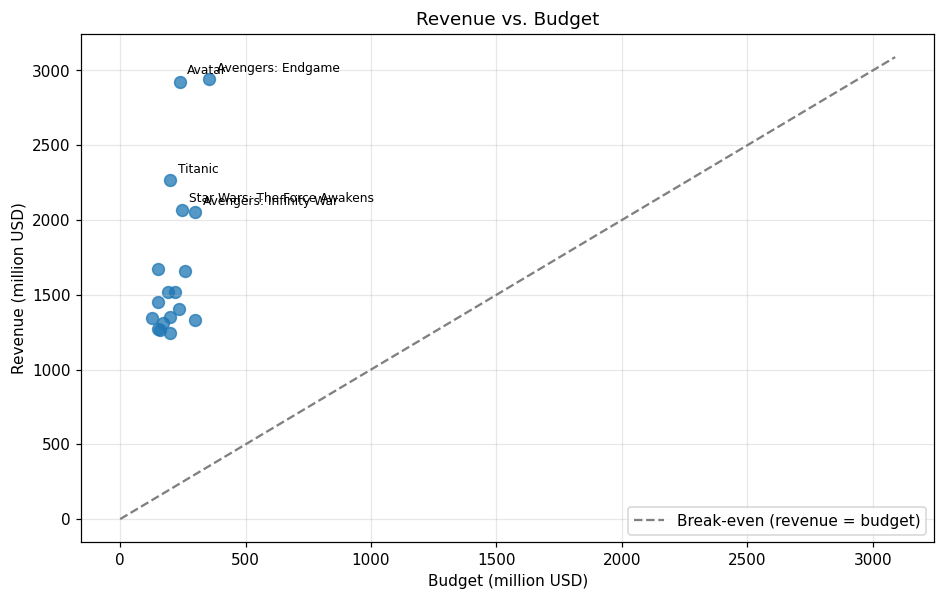

In [24]:
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

pdf = (kpi_df.where(F.col("budget_musd").isNotNull() & F.col("revenue_musd").isNotNull())
       .select("title", "budget_musd", "revenue_musd").toPandas())

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(pdf["budget_musd"], pdf["revenue_musd"], s=60, alpha=0.75)
upper = max(pdf["budget_musd"].max(), pdf["revenue_musd"].max()) * 1.05
ax.plot([0, upper], [0, upper], "--", color="grey", label="Break-even (revenue = budget)")
for _, row in pdf.nlargest(5, "revenue_musd").iterrows():
    ax.annotate(row["title"], (row["budget_musd"], row["revenue_musd"]),
                xytext=(5, 5), textcoords="offset points", fontsize=8)
ax.set(title="Revenue vs. Budget", xlabel="Budget (million USD)", ylabel="Revenue (million USD)")
ax.legend()
fig.savefig(FIGURES_DIR / "01_revenue_vs_budget.png", bbox_inches="tight")
plt.show()

### 4.2 ROI distribution by genre
Movies with several genres count in each genre. Genres are sorted by median ROI.

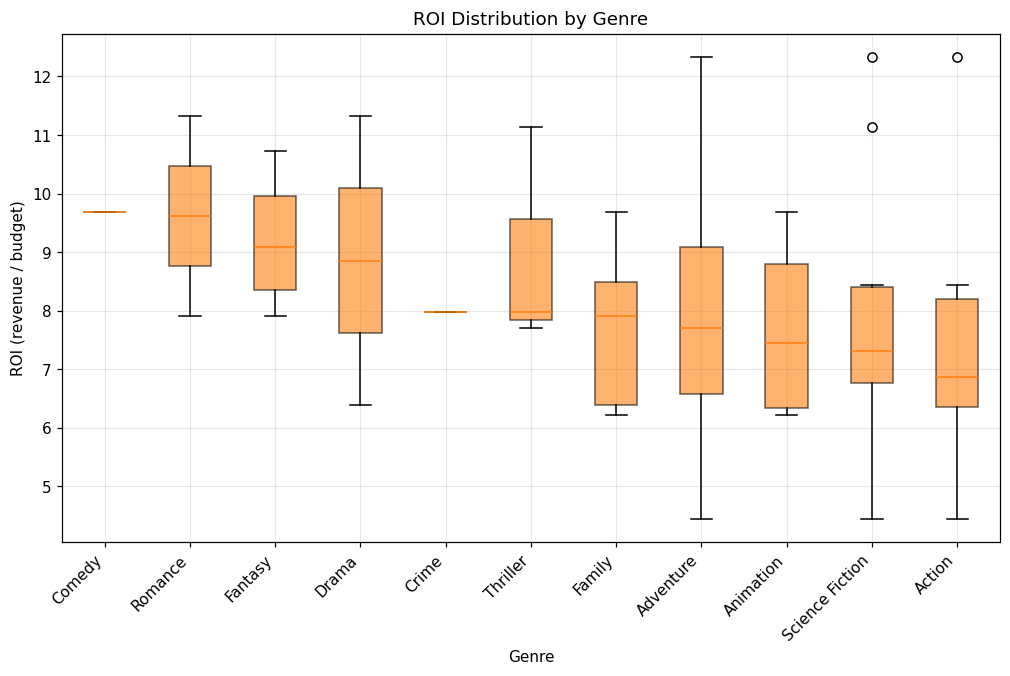

In [25]:
pdf = (kpi_df.where(F.col("roi").isNotNull() & F.col("genres").isNotNull())
       .select(F.explode(F.split("genres", r"\|")).alias("genre"), "roi").toPandas())
order = pdf.groupby("genre")["roi"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(11, 6))
ax.boxplot([pdf.loc[pdf["genre"] == g, "roi"] for g in order], patch_artist=True,
           boxprops={"facecolor": "tab:orange", "alpha": 0.6})
ax.set_xticks(range(1, len(order) + 1))
ax.set_xticklabels(order, rotation=45, ha="right")
ax.set(title="ROI Distribution by Genre", xlabel="Genre", ylabel="ROI (revenue / budget)")
fig.savefig(FIGURES_DIR / "02_roi_by_genre.png", bbox_inches="tight")
plt.show()

### 4.3 Popularity vs. rating
Bubble size and colour show the vote count. The correlation shows whether popular films are also the best rated.

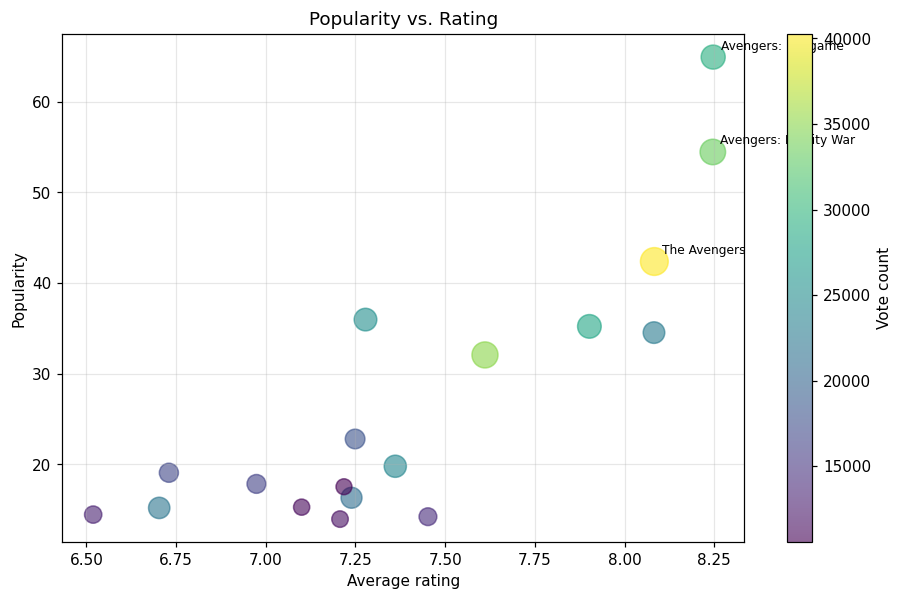

Correlation (popularity, rating): 0.84


In [26]:
pdf = (kpi_df.where(F.col("popularity").isNotNull() & F.col("vote_average").isNotNull())
       .select("title", "popularity", "vote_average", "vote_count").toPandas())

fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(pdf["vote_average"], pdf["popularity"],
                s=30 + 300 * pdf["vote_count"] / pdf["vote_count"].max(),
                c=pdf["vote_count"], cmap="viridis", alpha=0.6)
fig.colorbar(sc, ax=ax, label="Vote count")
for _, row in pdf.nlargest(3, "popularity").iterrows():
    ax.annotate(row["title"], (row["vote_average"], row["popularity"]),
                xytext=(5, 5), textcoords="offset points", fontsize=8)
ax.set(title="Popularity vs. Rating", xlabel="Average rating", ylabel="Popularity")
fig.savefig(FIGURES_DIR / "03_popularity_vs_rating.png", bbox_inches="tight")
plt.show()

print(f"Correlation (popularity, rating): {kpi_df.stat.corr('popularity', 'vote_average'):.2f}")

### 4.4 Yearly trends in box office performance
Total revenue and budget per release year (bars) and mean revenue per movie (line).

+----+------+------------------+-----------------+-----------------+
|year|movies|total_revenue_musd|mean_revenue_musd|total_budget_musd|
+----+------+------------------+-----------------+-----------------+
|1997|1     |2264.16           |2264.16          |200.0            |
|2009|1     |2923.71           |2923.71          |237.0            |
|2011|1     |1341.51           |1341.51          |125.0            |
|2012|1     |1518.82           |1518.82          |220.0            |
|2013|1     |1274.22           |1274.22          |150.0            |
|2015|4     |6660.57           |1665.14          |820.0            |
|2017|2     |2600.52           |1300.26          |460.0            |
|2018|4     |5956.04           |1489.01          |870.0            |
|2019|3     |6057.89           |2019.3           |766.0            |
+----+------+------------------+-----------------+-----------------+



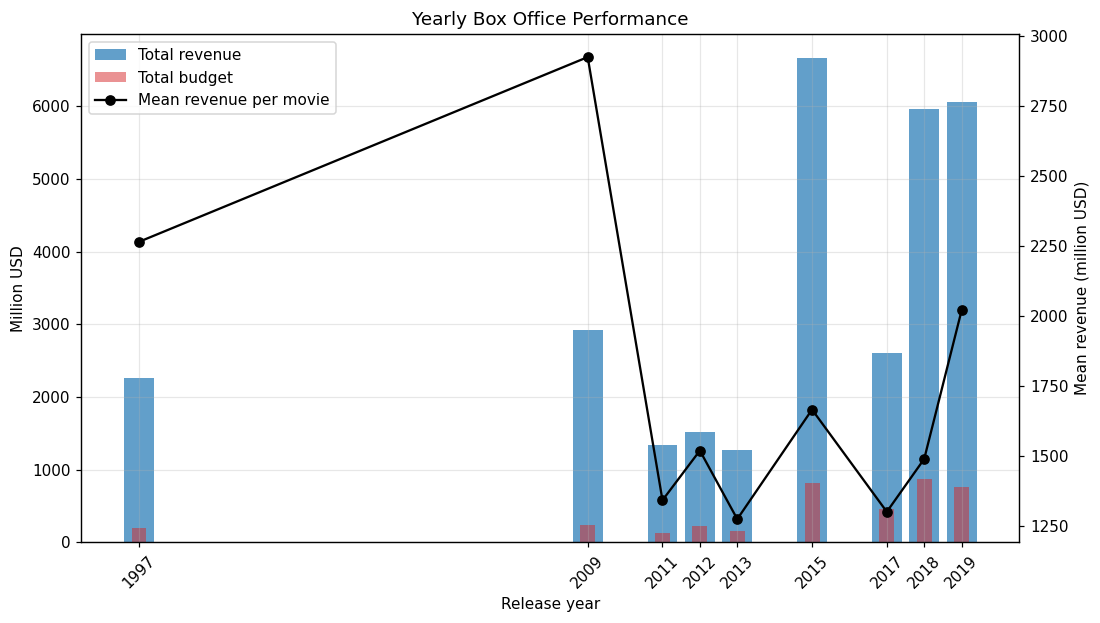

In [27]:
yearly = (kpi_df.where(F.col("release_date").isNotNull())
          .groupBy(F.year("release_date").alias("year"))
          .agg(F.count("*").alias("movies"),
               F.round(F.sum("revenue_musd"), 2).alias("total_revenue_musd"),
               F.round(F.mean("revenue_musd"), 2).alias("mean_revenue_musd"),
               F.round(F.sum("budget_musd"), 2).alias("total_budget_musd"))
          .orderBy("year"))
yearly.show(truncate=False)
pdf = yearly.toPandas()

fig, ax1 = plt.subplots(figsize=(11, 6))
ax1.bar(pdf["year"], pdf["total_revenue_musd"], alpha=0.7, label="Total revenue")
ax1.bar(pdf["year"], pdf["total_budget_musd"], color="tab:red", alpha=0.5, width=0.4,
        label="Total budget")
ax1.set(title="Yearly Box Office Performance", xlabel="Release year", ylabel="Million USD")
ax1.set_xticks(pdf["year"])
ax1.tick_params(axis="x", rotation=45)
ax2 = ax1.twinx()
ax2.plot(pdf["year"], pdf["mean_revenue_musd"], "o-", color="black", label="Mean revenue per movie")
ax2.set_ylabel("Mean revenue (million USD)")
ax2.grid(False)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left")
fig.savefig(FIGURES_DIR / "04_yearly_trends.png", bbox_inches="tight")
plt.show()

### 4.5 Franchise vs. standalone success
Side-by-side comparison of the two groups on each metric.

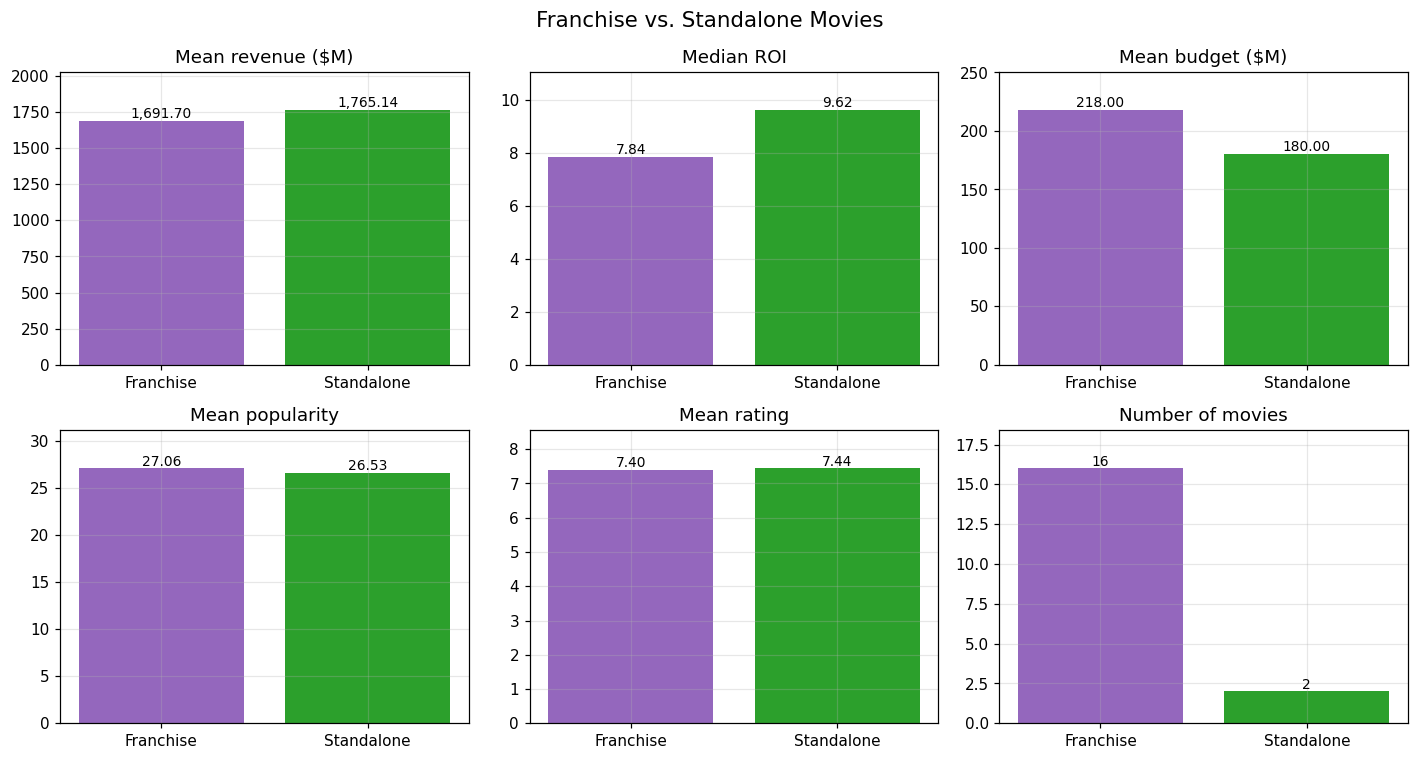

In [28]:
pdf = franchise_vs_standalone.toPandas().set_index("movie_type")
metrics = {"mean_revenue_musd": "Mean revenue ($M)", "median_roi": "Median ROI",
           "mean_budget_musd": "Mean budget ($M)", "mean_popularity": "Mean popularity",
           "mean_rating": "Mean rating", "movie_count": "Number of movies"}
colors = {"Franchise": "tab:purple", "Standalone": "tab:green"}

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (col, label) in zip(axes.flat, metrics.items()):
    values = pdf[col].fillna(0)
    ax.bar(values.index, values.values, color=[colors[i] for i in values.index])
    ax.set_title(label)
    ax.margins(y=0.15)
    for i, v in enumerate(values.values):
        ax.text(i, v, f"{v:,.2f}" if col != "movie_count" else f"{int(v)}",
                ha="center", va="bottom", fontsize=9)
fig.suptitle("Franchise vs. Standalone Movies", fontsize=14)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_franchise_vs_standalone.png", bbox_inches="tight")
plt.show()

## Step 5: Final Report
Writes `reports/final_report.md` from the computed results (key insights, methodology, KPI tables, search results, franchise and director analysis, charts), so every number matches the data actually fetched.

In [29]:
def to_md(sdf: DataFrame) -> str:
    pdf = sdf.toPandas()
    if pdf.empty:
        return "_No rows returned._"
    cell = lambda v: "" if pd.isna(v) else (f"{v:,.2f}" if isinstance(v, float) else str(v).replace("|", "\\|"))
    lines = ["| " + " | ".join(pdf.columns) + " |", "|" + " --- |" * len(pdf.columns)]
    lines += ["| " + " | ".join(cell(v) for v in row) + " |" for row in pdf.itertuples(index=False)]
    return "\n".join(lines)


top = rankings["Highest Revenue"].first()
best_profit = rankings["Highest Profit"].first()
best_roi, worst_roi = rankings["Highest ROI (budget >= $10M)"].first(), rankings["Lowest ROI (budget >= $10M)"].first()
top_franchise, top_director = franchises.first(), directors.first()
losses = kpi_df.where(F.col("profit_musd") < 0).count()
known = kpi_df.where(F.col("profit_musd").isNotNull()).count()
corr = kpi_df.stat.corr("popularity", "vote_average")

insights = [
    f"**{top['title']}** is the highest-grossing film at **${top['revenue_musd']:,.0f}M**.",
    f"**{best_profit['title']}** made the largest profit (**${best_profit['profit_musd']:,.0f}M**).",
    f"ROI ranges from **{worst_roi['roi']:.2f}x** ({worst_roi['title']}) to **{best_roi['roi']:.2f}x** ({best_roi['title']}).",
    f"{known - losses} of {known} movies with known budget and revenue were profitable.",
    f"Top franchise by revenue: **{top_franchise['franchise']}** ({top_franchise['movie_count']} films, ${top_franchise['total_revenue_musd']:,.0f}M).",
    f"Top director by revenue: **{top_director['director']}** ({top_director['movies_directed']} films, ${top_director['total_revenue_musd']:,.0f}M).",
    f"Correlation between popularity and rating: r = {corr:.2f}.",
]

sections = [
    "# TMDB Movie Data Analysis with PySpark: Final Report",
    "## 1. Key Insights\n\n" + "\n".join(f"- {i}" for i in insights),
    "## 2. Methodology\n\n"
    "**Extraction:** TMDB `/movie/{id}` with `append_to_response=credits`; retries on 429/5xx; "
    f"invalid IDs skipped; raw JSON cached. {len(MOVIE_IDS)} IDs requested, {raw_df.count()} returned.\n\n"
    "**Cleaning:** dropped irrelevant columns; flattened nested JSON into pipe-separated strings; "
    "derived cast, director, cast_size and crew_size from credits; cast types; zero budget/revenue/runtime "
    "set to null; money in millions USD; ratings with 0 votes nulled; text placeholders nulled; removed "
    "duplicates, rows without id/title and rows with < 10 non-null values; kept Released movies only. "
    f"Final dataset: {clean_df.count()} movies.\n\n"
    "**Analysis:** profit and ROI added; a reusable ranking UDF (`rank_movies`) produces all rankings; "
    "grouped aggregations for franchises, standalone movies and directors; Matplotlib charts.",
    "## 3. KPI Rankings\n\n" + "\n\n".join(f"### {n}\n\n{to_md(r)}" for n, r in rankings.items()),
    "## 4. Search Queries\n\n"
    f"### Search 1: Sci-Fi Action with Bruce Willis\n\n{to_md(search_scifi_action_bruce_willis(kpi_df))}\n\n"
    f"### Search 2: Uma Thurman directed by Tarantino\n\n{to_md(search_uma_thurman_tarantino(kpi_df))}\n\n"
    "The assigned dataset has no such films, so empty results are correct. On the validation set:\n\n"
    f"{to_md(search_scifi_action_bruce_willis(validation_df))}\n\n{to_md(search_uma_thurman_tarantino(validation_df))}",
    "## 5. Franchise vs. Standalone\n\n" + to_md(franchise_vs_standalone),
    "## 6. Most Successful Franchises\n\n" + to_md(franchises),
    "## 7. Most Successful Directors\n\n" + to_md(directors.limit(10)),
    "## 8. Yearly Box Office\n\n" + to_md(yearly),
    "## 9. Visualizations\n\n" + "\n\n".join(f"![{f}](figures/{f}.png)" for f in [
        "01_revenue_vs_budget", "02_roi_by_genre", "03_popularity_vs_rating",
        "04_yearly_trends", "05_franchise_vs_standalone"]),
    "## 10. Conclusions\n\n"
    "- The dataset is a curated list of top-grossing blockbusters, not a random sample, so findings describe blockbusters only.\n"
    "- Franchise films dominate, reflecting studios' focus on proven intellectual property.\n"
    "- Higher budgets bring higher revenue but not necessarily higher ROI.\n"
    "- Popularity is a daily-changing activity score and is only loosely linked to rating.\n"
    "- Revenues are not inflation-adjusted; a larger sample (e.g. via `/discover`) would strengthen the conclusions.",
]
(REPORTS_DIR / "final_report.md").write_text("\n\n".join(sections) + "\n", encoding="utf-8")
print(f"Report saved to {REPORTS_DIR / 'final_report.md'}\n")
print("\n".join(insights))

Report saved to c:\Users\PC\Desktop\Amalitech1\tmdb-spark-analysis\reports\final_report.md

**Avengers: Endgame** is the highest-grossing film at **$2,942M**.
**Avatar** made the largest profit (**$2,687M**).
ROI ranges from **4.45x** (Star Wars: The Last Jedi) to **12.34x** (Avatar).
18 of 18 movies with known budget and revenue were profitable.
Top franchise by revenue: **The Avengers Collection** (4 films, $7,919M).
Top director by revenue: **James Cameron** (2 films, $5,188M).
Correlation between popularity and rating: r = 0.84.


## Conclusions
- **Blockbuster economics:** the movies are among the highest-grossing ever, so results describe blockbusters, not the whole industry.
- **Franchises dominate:** most titles belong to a collection; the standalone group is small, so that comparison is indicative.
- **Revenue ≠ profitability:** bigger budgets bring bigger revenue, but ROI varies widely.
- **Popularity ≠ quality:** popularity and rating are only loosely related.
- **Limitations:** small hand-picked sample, no inflation adjustment, no marketing costs.

In [30]:
spark.stop()